# T5 colour binding probe

Is "which spot holds the named colour" learnable from the VAE latents at all? (Done as a script on
2026-11-13, step 07: 89% from 135 scenes, 100% from 1,000. Rebuilt here step by step.)


In [8]:
import sys

import numpy as np
import torch

from dream_robot.policies.verne.data import REPO, WORDS

sys.path.insert(0, '..')  # nbs/probe.py
from probe import probe, show

## The scenes: 1,300 T5 resets, first frame through the VAE (cached by the script)


In [9]:
d = np.load(REPO / 'scratch/verne07/t5_scenes.npz')
show(list(d), d['z'].shape, d['c'][:10], d['y'][:10])

list(d) = ['z', 'c', 'y']
d['z'].shape = (1300, 4, 16, 32)
d['c'][:10] = array([2, 2, 0, 1, 1, 2, 0, 2, 0, 0])
d['y'][:10] = array([0, 0, 1, 0, 0, 1, 0, 0, 1, 1])


**1,300 scenes: latent `z` [4, 16, 32] each, colour `c` (index into WORDS: 0 red, 1 green, 2 blue,
3 yellow), label `y` = the named cube's slot (0 near spot, 1 far spot).**

- Only the first frame of each reset: no demo, no actions. The question is purely "can you find the
  named colour in this latent?"
- The side word isn't here: it's already perfect in the policy (0 wrong bin).


## Decode 4 latents back to pictures


In [10]:
from dream_robot.policies.verne import vae

enc = vae.load(vae.WEIGHTS)
z4 = torch.tensor(d['z'][:4]).cuda().float()
with torch.no_grad():  # undo the per-channel normalisation, then the decoder
    raw = z4 * enc.z_std[:, None, None] + enc.z_mean[:, None, None]
    pics = ((enc.dec(raw).clamp(-1, 1) + 1) * 127.5).byte().permute(0, 2, 3, 1).cpu().numpy()
show(pics.shape)

pics.shape = (4, 128, 256, 3)


**Decoded canvases [4, 128, 256, 3]: [top | wrist], as the policy sees them.**


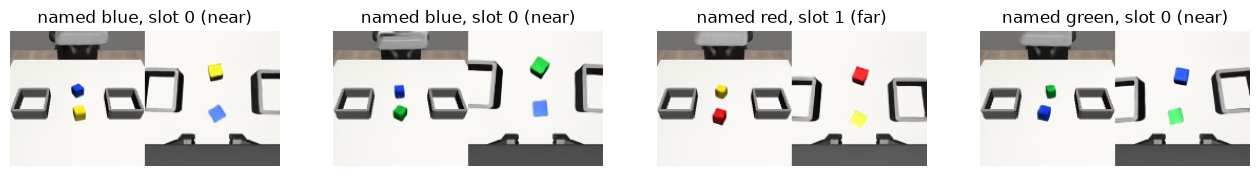

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 2.4))
for i, ax in enumerate(axes):
    ax.imshow(pics[i])
    ax.set_title(
        f'named {WORDS[d["c"][i]]}, slot {d["y"][i]} ({"near" if d["y"][i] == 0 else "far"})'
    )
    ax.axis('off')

**Labels match the pictures: in the top view (left half) the robot is at the top, so slot 0 (near)
is the upper cube and slot 1 (far) the lower one.**

- Scene 1: named blue, blue is the upper cube → slot 0. Scene 3: named red, red is the lower → slot 1.
- The colours survive the VAE (blue, green, red, yellow all distinct), and each cube is a few patches.
- The wrist view (right half) shows the same two cubes larger, from the gripper's camera.
- So the answer is in the picture: "named colour + where that colour is" → slot.


## The probe's input: latent + the named colour tiled as 4 constant channels


In [12]:
import torch.nn.functional as F

z, c, y = (torch.tensor(d[k]).cuda() for k in ('z', 'c', 'y'))
colour = F.one_hot(c[:2], 4).float()  # [2, 4]: scene 0 blue, scene 1 blue
tiled = colour[:, :, None, None].expand(-1, -1, 16, 32)  # the same 4 numbers at every latent cell
x = torch.cat([z[:2].float(), tiled], 1)
show(colour, tiled.shape, x.shape, x[0, 4:, 0, 0], x[0, 4:, 9, 20])

colour =
tensor([[0., 0., 1., 0.],
        [0., 0., 1., 0.]], device='cuda:0')
tiled.shape = torch.Size([2, 4, 16, 32])
x.shape = torch.Size([2, 8, 16, 32])
x[0, 4:, 0, 0] = tensor([0., 0., 1., 0.], device='cuda:0')
x[0, 4:, 9, 20] = tensor([0., 0., 1., 0.], device='cuda:0')


**Input [2, 8, 16, 32]: channels 0-3 the latent, 4-7 the colour one-hot, the same at every cell
(blue = [0, 0, 1, 0] at (0, 0) and at (9, 20)).**

- Tiling puts the question next to every piece of the picture: a 3x3 conv at any cell sees both
  "what's here" (latent) and "which colour am I looking for" (one-hot), so it can fire where they match.
- In the policy the colour arrives as a token (step 08) or word rows (step 11), and attention has to
  bring it to the right patches; here it's handed to every cell for free. An easier setting on purpose.


## The probe: 3 conv layers → average over the grid → 2 logits (near, far)


In [ ]:
from torch import nn

torch.manual_seed(0)
net = nn.Sequential(
    nn.Conv2d(8, 64, 3, padding=1), nn.GELU(),
    nn.Conv2d(64, 64, 3, padding=1),
    nn.GELU(),
    nn.Conv2d(64, 64, 3, padding=1),
    nn.GELU(), nn.AdaptiveAvgPool2d(1),
    nn.Flatten(), nn.Linear(64, 2),
).cuda()
show(net[:6](x).shape, net(x).shape, net(x), sum(p.numel() for p in net.parameters()))

net[:6](x).shape = torch.Size([2, 64, 16, 32])
net(x).shape = torch.Size([2, 2])
net(x) =
tensor([[-0.0474, -0.0210],
        [-0.0463, -0.0210]], device='cuda:0', grad_fn=<AddmmBackward0>)
sum(p.numel() for p in net.parameters()) = 78658


**After the convs [2, 64, 16, 32] (grid kept); after pooling + linear [2, 2]: one logit for near, one
for far. 78,658 params. Untrained: both scenes ≈ the same logits.**

- 3 stacked 3x3 convs see 7x7 latent cells around each cell (112x112 px of canvas): enough to cover a cube
  and the cells next to it, not the whole table.
- The average pool then asks "over the whole grid, how much near-ish vs far-ish evidence?" — so a
  cell that finds the named colour has to also encode _where_ it is (the latent carries position via
  what's around it: bins, table edge, the other camera half).


## Training: a fresh copy of the probe on the first n scenes, scored on scenes 1000-1299


In [14]:
import copy


def inputs(ids):
    tiled = F.one_hot(c[ids], 4).float()[:, :, None, None].expand(-1, -1, 16, 32)
    return torch.cat([z[ids].float(), tiled], 1)


@torch.no_grad()
def accuracy(p, ids):
    return (p(inputs(ids)).argmax(1) == y[ids]).float().mean().item()


def fit(n_train, steps=3000):
    # -> (train accuracy, held-out accuracy); AdamW 1e-3, batch 64, cross-entropy on near/far
    p = copy.deepcopy(net)  # the untrained probe above, so every call starts the same
    opt = torch.optim.AdamW(p.parameters(), lr=1e-3, weight_decay=1e-2)
    tr, va = torch.arange(n_train).cuda(), torch.arange(1000, 1300).cuda()
    g = torch.Generator('cuda').manual_seed(0)
    for _ in range(steps):
        ids = tr[torch.randint(0, n_train, (64,), device='cuda', generator=g)]
        loss = F.cross_entropy(p(inputs(ids)), y[ids])
        opt.zero_grad()
        loss.backward()
        opt.step()
    return accuracy(p, tr), accuracy(p, va)

## 135 scenes (the T5 demo count)


In [15]:
show(fit(135))

fit(135) = (1.0, 0.8866667151451111)


**135 scenes: train 100%, held-out 89% (266 of 300; chance 50%).** Same as the script.

- From as many scenes as T5 has demos, a 79k-param conv net learns "find the named colour, say where"
  well: the information is in the latents, and 135 examples nearly suffice when that's the only job.
- Train 100% vs held-out 89%: it memorises some of the 135; more scenes should close the gap.


## 1,000 scenes


In [16]:
show(fit(1000))

fit(1000) = (1.0, 1.0)


**1,000 scenes: train 100%, held-out 100%.** The memorising gap is gone.

## What this says

| scenes | train | held-out |
|---|---|---|
| 135 (the demo count) | 100% | 89% |
| 1,000 | 100% | 100% |

- **The latents carry it.** Colour and place survive the VAE well enough that "which spot holds the
  named colour" is easy, for a model whose only job is that question, with the colour at every cell.
- **The policy has the information but doesn't use it.** T5 picks the named cube at chance (22/50 with
  the word token, 14/50 with cross-attention). Its loss is mostly motion; which cube is a small part of it.
- **Where the easy setting differs from the policy:** here the colour is tiled onto every cell and the
  label is the answer itself. In the policy the colour arrives through attention and the only signal is
  the actions, so 135 demos give it far less to learn the binding from.
- **Matches step 09b:** the same answer as a sim label on 1,000 demo-less scenes took the policy from
  22 to 44 of 50. Data for the binding, not wiring, is what moved it.